Завантаження та нормалізація даних MNIST

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from keras.datasets import mnist
from keras.models import Sequential, load_model
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPooling2D, Input
from keras import utils
from keras.utils import to_categorical, load_img, img_to_array
from sklearn.model_selection import KFold

(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train_norm = X_train / 255.0
X_test_norm = X_test / 255.0

print(f"Розмірність навчальних даних: {X_train.shape}")
print(f"Розмірність тестових даних: {X_test.shape}")


Розмірність навчальних даних: (60000, 28, 28)
Розмірність тестових даних: (10000, 28, 28)


Клас Callback та навчання моделі до 99% точності

In [5]:
class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.99:
            print("\nReached 99% accuracy so cancelling training!")
            print(f"Досягнуто 99% точності на епосі {epoch + 1}, тому скасовуємо навчання!")
            self.model.stop_training = True

def train_mnist(x_train, y_train):
    callbacks = myCallback()
    
    model = Sequential([
        Flatten(input_shape=(28, 28)),
        Dense(512, activation='relu'),
        Dense(10, activation='softmax')
    ])
    
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    
    history = model.fit(x_train, y_train, epochs=10, callbacks=[callbacks], verbose=1)
    return history

hist = train_mnist(X_train_norm, y_train)


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9410 - loss: 0.2008
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9758 - loss: 0.0791
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9841 - loss: 0.0515
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9879 - loss: 0.0373
Epoch 5/10
1869/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9915 - loss: 0.0265
Reached 99% accuracy so cancelling training!
Досягнуто 99% точності на епосі 5, тому скасовуємо навчання!
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9915 - loss: 0.0265


Візуалізація перших 4 зображень

In [7]:
num_pixels = 28 * 28
X_train_flat = X_train_norm.reshape(X_train_norm.shape[0], num_pixels).astype('float32')
X_test_flat = X_test_norm.reshape(X_test_norm.shape[0], num_pixels).astype('float32')

y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print(f"Форма плоского вектора: {X_train_flat.shape}")
print(f"Приклад one-hot мітки для n=101: {y_train_cat[101]}")


Форма плоского вектора: (60000, 784)
Приклад one-hot мітки для n=101: [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


Базова модель багатошарового персептрона (MLP)

In [8]:
def baseline_model():
    model = Sequential([
        Dense(num_pixels, input_shape=(num_pixels,), kernel_initializer='normal', activation='relu'),
        Dense(10, kernel_initializer='normal', activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_dense = baseline_model()
model_dense.summary()


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 784)            │       615,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 623,290 (2.38 MB)

 Trainable params: 623,290 (2.38 MB)

 Non-trainable params: 0 (0.00 B)

Навчання та оцінка базової моделі

In [9]:
history_dense = model_dense.fit(X_train_flat, y_train_cat, validation_data=(X_test_flat, y_test_cat), epochs=10, batch_size=200, verbose=2)

scores_dense = model_dense.evaluate(X_test_flat, y_test_cat, verbose=0)
print(f"Baseline Error: {100 - scores_dense[1] * 100:.2f}%")
print(f"Baseline Accuracy: {scores_dense[1] * 100:.2f}%")


Epoch 1/10
300/300 - 3s - 10ms/step - accuracy: 0.9225 - loss: 0.2766 - val_accuracy: 0.9568 - val_loss: 0.1438
Epoch 2/10
300/300 - 2s - 5ms/step - accuracy: 0.9682 - loss: 0.1104 - val_accuracy: 0.9722 - val_loss: 0.0923
Epoch 3/10
300/300 - 2s - 5ms/step - accuracy: 0.9793 - loss: 0.0708 - val_accuracy: 0.9762 - val_loss: 0.0786
Epoch 4/10
300/300 - 2s - 5ms/step - accuracy: 0.9858 - loss: 0.0494 - val_accuracy: 0.9765 - val_loss: 0.0727
Epoch 5/10
300/300 - 2s - 5ms/step - accuracy: 0.9902 - loss: 0.0356 - val_accuracy: 0.9786 - val_loss: 0.0646
Epoch 6/10
300/300 - 1s - 5ms/step - accuracy: 0.9925 - loss: 0.0262 - val_accuracy: 0.9800 - val_loss: 0.0610
Epoch 7/10
300/300 - 2s - 5ms/step - accuracy: 0.9949 - loss: 0.0197 - val_accuracy: 0.9809 - val_loss: 0.0610
Epoch 8/10
300/300 - 2s - 5ms/step - accuracy: 0.9961 - loss: 0.0155 - val_accuracy: 0.9816 - val_loss: 0.0588
Epoch 9/10
300/300 - 2s - 6ms/step - accuracy: 0.9980 - loss: 0.0107 - val_accuracy: 0.9811 - val_loss: 0.0607


# ============================================================
# ЗАВДАННЯ 5.2: Багатошаровий персептрон (MLP) з 1 прихованим шаром
# ============================================================
# Архітектура згідно лекційного завдання: 784 входів -> 784 нейрони ReLU -> 10 Softmax
def baseline_model():
    model = Sequential([
        Dense(num_pixels, input_shape=(num_pixels,), kernel_initializer='normal', activation='relu'),
        Dense(10, kernel_initializer='normal', activation='softmax')
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

# Ініціалізація та вивід структури базової моделі персептрона
model_dense = baseline_model()
model_dense.summary()


In [10]:
model_dense.save("mnist_dense.keras")
try:
    model_dense.save("mnist_dense.h5")
except:
    pass
print("Модель збережено")


Модель збережено


Розпізнавання тестового зразка персептроном

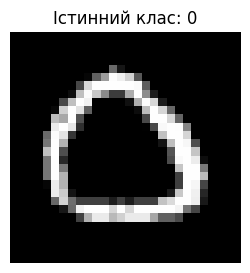

Передбачений клас: 0
Істинний клас: 0


In [11]:
n_rec = 126
plt.figure(figsize=(3, 3))
plt.imshow(X_test[n_rec], cmap='gray')
plt.title(f"Істинний клас: {y_test[n_rec]}")
plt.axis('off')
plt.show()

x_sample = np.expand_dims(X_test_flat[n_rec], axis=0)
prediction = model_dense.predict(x_sample, verbose=0)
print(f"Передбачений клас: {np.argmax(prediction)}")
print(f"Істинний клас: {y_test[n_rec]}")


Розпізнавання власного зображення персептроном

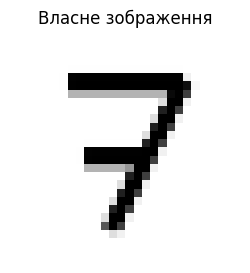

Розпізнана цифра: 7
Впевненість: 98.32%


In [12]:
img_path = 'my_digits/digit_7.png'
img = load_img(img_path, target_size=(28, 28), color_mode="grayscale")

plt.figure(figsize=(3, 3))
plt.imshow(img, cmap='gray')
plt.title("Власне зображення")
plt.axis('off')
plt.show()

x_custom = img_to_array(img).reshape(1, 784)
x_custom = (255.0 - x_custom) / 255.0

pred_custom = model_dense.predict(x_custom, verbose=0)
print(f"Розпізнана цифра: {np.argmax(pred_custom)}")
print(f"Впевненість: {np.max(pred_custom) * 100:.2f}%")


Згорткова модель з callback на 99.5% точності

In [13]:
X_train_cnn = X_train_norm.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test_norm.reshape(-1, 28, 28, 1).astype('float32')

class myCallback995(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') is not None and logs.get('accuracy') >= 0.995:
            print("\nReached 99.5% accuracy so cancelling training!")
            print(f"Досягнуто 99,5% точності на епосі {epoch + 1}, тому скасовуємо навчання!")
            self.model.stop_training = True

model_cnn_cb = Sequential([
    Conv2D(64, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    MaxPooling2D(2, 2),
    Flatten(),
    Dense(512, activation='relu'),
    Dense(10, activation='softmax')
])

model_cnn_cb.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cnn_cb.fit(X_train_cnn, y_train, epochs=10, batch_size=128, callbacks=[myCallback995()], verbose=1)


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 47ms/step - accuracy: 0.9511 - loss: 0.1649
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.9859 - loss: 0.0473
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 22s 47ms/step - accuracy: 0.9906 - loss: 0.0296
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 48ms/step - accuracy: 0.9944 - loss: 0.0181
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.9967 - loss: 0.0110
Reached 99.5% accuracy so cancelling training!
Досягнуто 99,5% точності на епосі 5, тому скасовуємо навчання!
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 49ms/step - accuracy: 0.9967 - loss: 0.0110


Проста згорткова мережа (Simple CNN)